# Data checks

The SQL queries audit the full dataset. Feature differences are compared with the approximate SMD variation under simple random assignment. The observed differences are too large to support randomisation within the released sample.

Results are loaded from the saved analysis outputs.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / 'results/full-run'
def table(name):
    frame = pd.read_csv(RESULTS / name)
    for column in frame.columns:
        if column == "two_sided_p_value":
            frame[column] = frame[column].map(lambda x: "< 1e-300" if x < 1e-300 else format(x, ".3g"))
        elif column.startswith("expected_loss_"):
            frame[column] = frame[column].map(lambda x: format(x, ".3e"))
    display(frame)
def figure(name):
    display(Image(filename=str(RESULTS / "figures" / name)))
def record(name):
    return json.loads((RESULTS / name).read_text())


,treatment,n,visit_sum,conversion_sum,exposure_sum,visit_exposure_sum,conversion_exposure_sum
0,0,2096937,80105,4063,0,0,0
1,1,11882655,576824,36711,428212,177510,23031


,feature,mean_0,mean_1,std_0,std_1,smd
0,f0,19.651705,19.614755,5.388112,5.375564,-0.006866
1,f1,10.067935,10.070337,0.092990,0.106693,0.023994
2,f2,8.448173,8.446302,0.300676,0.299075,-0.006241
3,f3,4.232821,4.169412,1.242029,1.352432,-0.048836
4,f4,10.336526,10.339245,0.338681,0.344117,0.007966
5,f5,4.039339,4.026602,0.395538,0.437045,-0.030557
6,f6,-3.999880,-4.182792,4.441985,4.600940,-0.040448
7,f7,5.080284,5.105555,1.163292,1.212461,0.021270
8,f8,3.934652,3.933392,0.055445,0.056869,-0.022433
9,f9,15.886253,16.052589,6.802162,7.056251,0.024001


{'reference': 'Approximate SMD standard deviation under simple random assignment: sqrt(1/n1 + 1/n0)',
 'n_treatment': 11882655,
 'n_control': 2096937,
 'randomisation_sd': 0.000749027586326405,
 'n_features': 12,
 'n_below_smd_0_1': 12,
 'min_absolute_smd': 0.005159528554154,
 'max_absolute_smd': 0.0488363403045533,
 'min_absolute_randomisation_z': 6.888302444852308,
 'max_absolute_randomisation_z': 65.1996551209421,
 'features': [{'feature': 'f0',
   'smd': -0.0068656192802077,
   'randomisation_z': -9.16604328804501},
  {'feature': 'f1',
   'smd': 0.0239943938024232,
   'randomisation_z': 32.03405887906393},
  {'feature': 'f2',
   'smd': -0.0062409889677054,
   'randomisation_z': -8.332121648969219},
  {'feature': 'f3',
   'smd': -0.0488363403045533,
   'randomisation_z': -65.1996551209421},
  {'feature': 'f4',
   'smd': 0.0079656612293337,
   'randomisation_z': 10.634670037189379},
  {'feature': 'f5',
   'smd': -0.0305568305237969,
   'randomisation_z': -40.7953339524682},
  {'featu

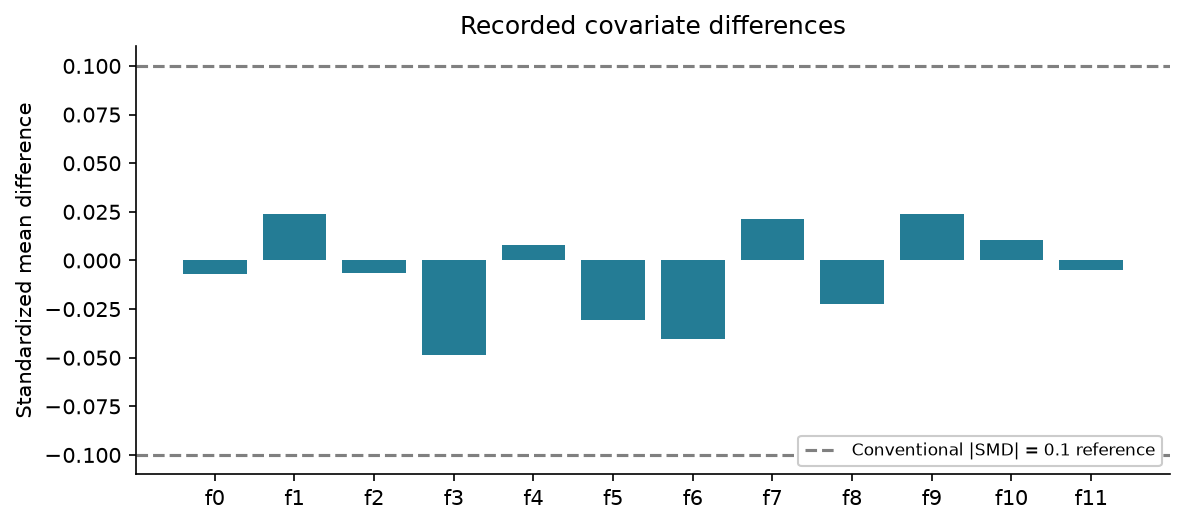

In [2]:
a = record("data_audit.json")
display(pd.DataFrame(a["groups"]))
table("feature_balance.csv")
display(record("balance_diagnostics.json"))
figure("balance.png")

In [3]:
m = record("manifest.json")
display({k: m[k] for k in ["git", "data_sha256", "seeds", "hardware"]})

{'git': {'commit': '6928958aac539e9314c5d992203a826e9d1e5037',
  'source': 'local_repository',
  'working_tree_dirty': False,
  'release_source_matches': True},
 'data_sha256': '2716e1bf0fd157a93b5bf86924d9088419dfbac2022c6cd90030220634f616dc',
 'seeds': {'analysis': 2026,
  'simulation_root': 2026,
  'split': 2026,
  'lightgbm': 2026,
  'targeting_tie_break': 2026,
  'uplift_row_bootstrap': 2027},
 'hardware': {'os': 'macOS-26.6.2-arm64-arm-64bit',
  'architecture': 'arm64',
  'cpu': 'Apple M4',
  'physical_cores': 10,
  'logical_cores': 10,
  'ram_bytes': 17179869184,
  'python': '3.12.14'}}